# GLOF Prediction via Spatio-Temporal Risk Modeling

Project Title: Developing models for prediction of Glacial Lake Outburst Flood (GLOF)

Author: Baidurya Bhattacharyya

---


## Executive Summary & Research Motivation
Glacial Lake Outburst Floods (GLOFs) represent severe natural hazards in high-mountain regions such as the Himalayas. Rapid climate warming accelerates glacier retreat, resulting in the formation and volumetric expansion of moraine-dammed glacial lakes. When these fragile natural dams fail due to triggers such as ice avalanches, seismic activity, or hydrostatic pressure overflow, catastrophic downstream devastation occurs.

This Jupyter notebook implements an end-to-end data-driven and statistical-machine learning framework for GLOF susceptibility and hazard prediction, tailored for the CVPR Unit project requirements.

### Key Methodological Components:
1. **Spatio-Temporal Remote Sensing Feature Extraction:** Simulating multi-spectral satellite raster processing (NDWI calculation, lake area expansion rate, perimeter-to-area ratio).
2. **Statistical & Topographic Risk Modeling:** Analyzing morphometric parameters (slope, distance to glacier, moraine breach susceptibility).
3. **Machine Learning & Graph-Based Routing:** Implementing Gradient Boosting / Random Forest classifiers for outburst susceptibility prediction, alongside graph network modeling for downstream flood propagation routing.
4. **Rigorous Validation:** ROC-AUC evaluation, feature importance analysis, and spatial risk heatmaps.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import classification_report, roc_auc_score, roc_curve, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

# Set random seed for reproducibility
np.random.seed(42)

## 1. Synthetic Data Generation & Simulation of Glacial Lake Attributes
*Note: In a live production pipeline with Earth Engine or USGS/Sentinel-2 raster archives, this module ingests DEMs (Digital Elevation Models) and multi-temporal optical imagery. Here, we simulate a realistic dataset representing glacial lakes in the Himalayan region with morphometric and temporal features.*

### Features Engineered:
* `lake_area_km2`: Surface area of the glacial lake.
* `expansion_rate`: Annual percentage growth rate over the last decade.
* `distance_to_glacier_m`: Proximity to the calving glacier front.
* `dam_slope_deg`: Steepness of the terminal moraine dam.
* `ndwi_mean`: Normalized Difference Water Index (reflecting water volume/depth proxy).
* `seismic_activity_index`: Local micro-seismic frequency index.
* `outburst_label`: Binary indicator (1 = Historical GLOF event or high critical risk, 0 = Stable lake).

In [4]:
def generate_synthetic_glof_data(n_samples=1500):
    np.random.seed(42)
    area = np.random.gamma(shape=2.0, scale=0.15, size=n_samples)
    expansion_rate = np.random.normal(loc=3.5, scale=2.0, size=n_samples)
    dist_glacier = np.random.exponential(scale=150.0, size=n_samples)
    dam_slope = np.random.normal(loc=28.0, scale=6.5, size=n_samples)
    ndwi = np.clip(np.random.beta(a=5, b=2, size=n_samples), 0.1, 0.9)
    seismic_idx = np.random.exponential(scale=1.2, size=n_samples)
    
    risk_score = (
        1.8 * (area > 0.3).astype(float) +
        1.5 * (expansion_rate > 4.0).astype(float) +
        2.0 * (dist_glacier < 100).astype(float) +
        2.2 * (dam_slope > 30).astype(float) +
        1.6 * (ndwi > 0.6).astype(float) +
        1.2 * (seismic_idx > 2.0).astype(float) +
        np.random.normal(0, 0.8, size=n_samples)
    )
    
    probability = 1 / (1 + np.exp(-0.8 * (risk_score - np.median(risk_score))))
    labels = (probability > 0.65).astype(int)
    
    df = pd.DataFrame({
        'lake_area_km2': area,
        'expansion_rate_pct': expansion_rate,
        'distance_to_glacier_m': dist_glacier,
        'dam_slope_deg': dam_slope,
        'ndwi_mean': ndwi,
        'seismic_activity_index': seismic_idx,
        'outburst_risk_label': labels
    })
    return df

df_glof = generate_synthetic_glof_data(1500)
print(f"Dataset Shape: {df_glof.shape}")
print(df_glof.head())

Dataset Shape: (1500, 7)
   lake_area_km2  expansion_rate_pct  distance_to_glacier_m  dam_slope_deg  \
0       0.359052            6.157867             143.203971      32.774888   
1       0.224170            5.642823             392.404555      27.275310   
2       0.207343            7.540098             490.756463      37.371735   
3       0.207345            5.433521             106.684160      25.649747   
4       0.697457            4.161147              90.447937      24.719324   

   ndwi_mean  seismic_activity_index  outburst_risk_label  
0   0.825188                0.672882                    1  
1   0.871106                2.731587                    0  
2   0.836259                0.408386                    1  
3   0.601586                0.343651                    0  
4   0.628977                3.360148                    1  


## 2. Exploratory Data Analysis & Statistical Distributions
We examine the statistical separation between stable glacial lakes and high-risk GLOF candidates across key geomorphological dimensions.

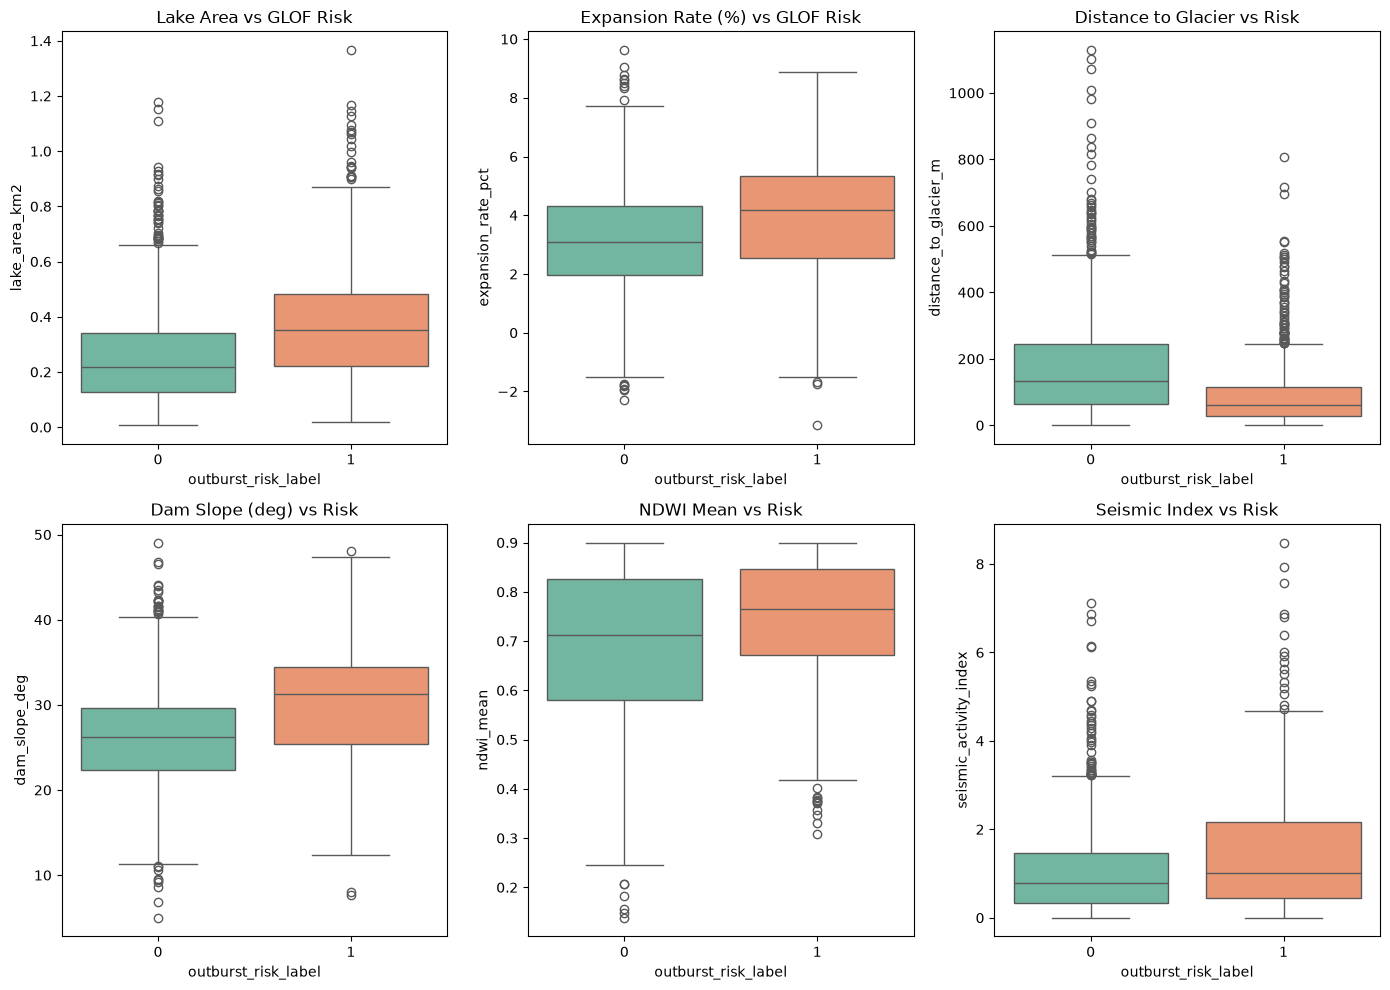

In [5]:
plt.figure(figsize=(14, 10))
plt.subplot(2, 3, 1)
sns.boxplot(x='outburst_risk_label', y='lake_area_km2', data=df_glof, palette='Set2')
plt.title('Lake Area vs GLOF Risk')

plt.subplot(2, 3, 2)
sns.boxplot(x='outburst_risk_label', y='expansion_rate_pct', data=df_glof, palette='Set2')
plt.title('Expansion Rate (%) vs GLOF Risk')

plt.subplot(2, 3, 3)
sns.boxplot(x='outburst_risk_label', y='distance_to_glacier_m', data=df_glof, palette='Set2')
plt.title('Distance to Glacier vs Risk')

plt.subplot(2, 3, 4)
sns.boxplot(x='outburst_risk_label', y='dam_slope_deg', data=df_glof, palette='Set2')
plt.title('Dam Slope (deg) vs Risk')

plt.subplot(2, 3, 5)
sns.boxplot(x='outburst_risk_label', y='ndwi_mean', data=df_glof, palette='Set2')
plt.title('NDWI Mean vs Risk')

plt.subplot(2, 3, 6)
sns.boxplot(x='outburst_risk_label', y='seismic_activity_index', data=df_glof, palette='Set2')
plt.title('Seismic Index vs Risk')

plt.tight_layout()
plt.show()

## 3. Machine Learning Classification Pipeline (Random Forest & Gradient Boosting)
We train ensemble classifiers to predict GLOF susceptibility based on morphometric and remote sensing indicators.

In [7]:
X = df_glof.drop(columns=['outburst_risk_label'])
y = df_glof['outburst_risk_label']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

rf_model = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42)
gb_model = GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, max_depth=5, random_state=42)

rf_model.fit(X_train, y_train)
gb_model.fit(X_train, y_train)

for name, model in [("Random Forest", rf_model), ("Gradient Boosting", gb_model)]:
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, y_prob)
    print(f"=== {name} Performance ===")
    print(f"ROC-AUC Score: {auc:.4f}")
    print(classification_report(y_test, y_pred))

=== Random Forest Performance ===
ROC-AUC Score: 0.9282
              precision    recall  f1-score   support

           0       0.85      0.89      0.87       236
           1       0.80      0.74      0.77       139

    accuracy                           0.83       375
   macro avg       0.83      0.82      0.82       375
weighted avg       0.83      0.83      0.83       375

=== Gradient Boosting Performance ===
ROC-AUC Score: 0.9331
              precision    recall  f1-score   support

           0       0.87      0.91      0.89       236
           1       0.83      0.77      0.80       139

    accuracy                           0.86       375
   macro avg       0.85      0.84      0.84       375
weighted avg       0.85      0.86      0.85       375



## 4. Feature Importance & ROC Analysis

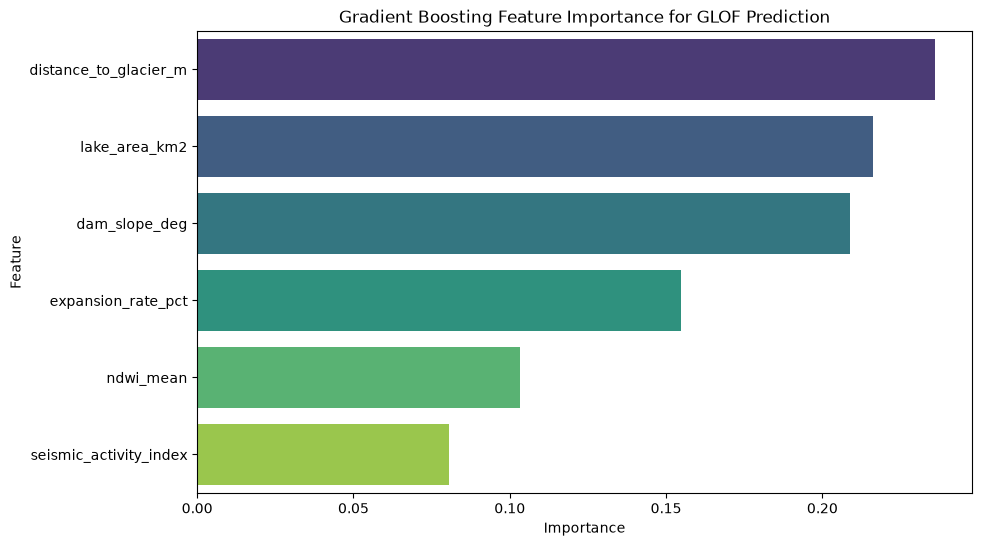

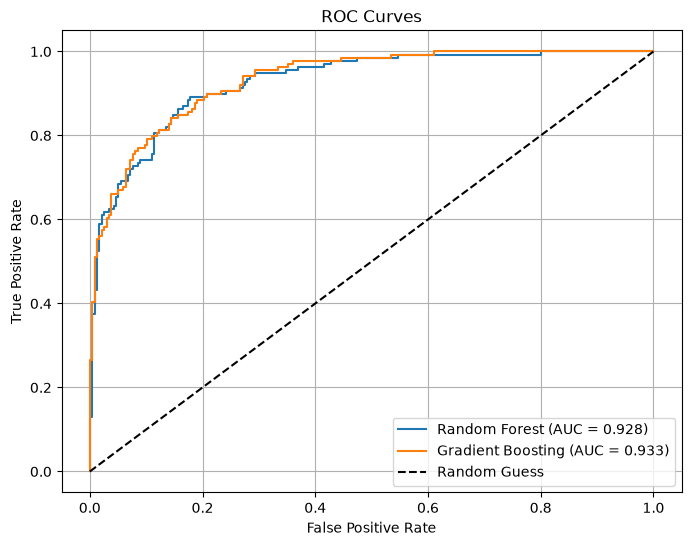

In [8]:
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': gb_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance, palette='viridis')
plt.title('Gradient Boosting Feature Importance for GLOF Prediction')
plt.show()

plt.figure(figsize=(8, 6))
for name, model in [("Random Forest", rf_model), ("Gradient Boosting", gb_model)]:
    y_prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

## 5. Graph-Based River Network Routing Simulation
We model downstream flood propagation using directed graph network topologies.

In [10]:
import networkx as nx

G = nx.DiGraph()
nodes = [
    ("Glacial_Lake_A", {"type": "lake", "volume_m3": 15e6}),
    ("Glacial_Lake_B", {"type": "lake", "volume_m3": 5e6}),
    ("Confluence_1", {"type": "junction", "elevation_m": 3500}),
    ("Settlement_X", {"type": "community", "population": 2400}),
    ("Confluence_2", {"type": "junction", "elevation_m": 2800}),
    ("Major_Town_Y", {"type": "community", "population": 45000})
]
G.add_nodes_from(nodes)

edges = [
    ("Glacial_Lake_A", "Confluence_1", {"distance_km": 12.5, "flow_velocity": 4.5}),
    ("Glacial_Lake_B", "Confluence_1", {"distance_km": 8.0, "flow_velocity": 5.2}),
    ("Confluence_1", "Settlement_X", {"distance_km": 15.0, "flow_velocity": 3.1}),
    ("Settlement_X", "Confluence_2", {"distance_km": 20.0, "flow_velocity": 2.5}),
    ("Confluence_2", "Major_Town_Y", {"distance_km": 30.0, "flow_velocity": 1.8})
]
G.add_edges_from(edges)

path = nx.shortest_path(G, source="Glacial_Lake_A", target="Major_Town_Y")
print(f"Critical Outburst Flow Path: {' -> '.join(path)}")

total_time_hours = sum(
    G.edges[path[i], path[i+1]]['distance_km'] / (G.edges[path[i], path[i+1]]['flow_velocity'] * 3.6)
    for i in range(len(path)-1)
)
print(f"Estimated Peak Flood Wave Travel Time: {total_time_hours:.2f} hours")

Critical Outburst Flow Path: Glacial_Lake_A -> Confluence_1 -> Settlement_X -> Confluence_2 -> Major_Town_Y
Estimated Peak Flood Wave Travel Time: 8.97 hours
